### Установа библиотек

In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
from sklearn.impute import SimpleImputer
import seaborn as sns

### Загрузка данных

In [138]:
df = pd.read_csv("data.csv", skipinitialspace=True, sep=";", decimal=".", encoding="utf-8")
df.columns = df.columns.str.lower().str.replace(" ", "_")

In [139]:
df.head(10)

,год,время_года,климат,город,страна,способ_охлаждения,режим_при_смешанном_типе_охлаждения,способ_обогрева,возраст,пол,...,скорость_воздуха,рост,вес,занавески,вентилятор,окно,двери,отопление,среднемесячная_температура_на_улице,количество_рекламаций
0,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,22.0,NaN,...,0.26,NaN,NaN,1.0,1.0,NaN,NaN,NaN,28.9,0
1,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,40.0,NaN,...,0.12,NaN,NaN,0.0,0.0,NaN,NaN,NaN,84.0,0
2,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,42.0,NaN,...,0.08,NaN,NaN,0.0,0.0,NaN,NaN,NaN,32.8,0
3,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,27.0,NaN,...,27.16,NaN,NaN,1.0,1.0,NaN,NaN,NaN,28.9,1
4,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,46.0,NaN,...,63.83,NaN,NaN,1.0,1.0,NaN,NaN,NaN,32.8,0
5,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,27.0,NaN,...,0.21,NaN,NaN,1.0,1.0,NaN,NaN,NaN,28.9,0
6,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,32.0,NaN,...,0.10,NaN,NaN,1.0,1.0,NaN,NaN,NaN,32.8,0
7,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,30.0,NaN,...,0.09,NaN,NaN,0.0,0.0,NaN,NaN,NaN,32.8,0
8,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,43.0,NaN,...,0.15,NaN,NaN,1.0,1.0,NaN,NaN,NaN,32.8,0
9,2011.0,Лето,Cубтропический океанический,Техас,США,Кондиционирование,NaN,NaN,43.0,NaN,...,0.34,NaN,NaN,0.0,0.0,NaN,NaN,NaN,31.7,0


## Исследование данных на качество и предобработка
    1. Названия столбцов привести в соответствии с PEP8
    2. Исследовать типы данных, привести данные к правильному типу, где это необходимо
    3. Проверить данные на пропуски и заполнить их при необходимости. Обосновать решение.
    4. Проверить данные на явные и неявные (в категориальных столбцах) дубликаты. Обработать дубликаты.
    5. Провести аналитический и графический анализ данных. Сделать выводы.
    6. Проверить данные на выбросы и адекватность данных. Предположить причину возникновения выбросов и обработать такие значения.


### Названия столбцов привести в соответствии с PEP8

In [140]:
df.columns = df.columns.str.lower().str.replace(" ", "_")

### Исследовать типы данных, привести данные к правильному типу, где это необходимо

#### Узнать типы данных

In [141]:
print(df.dtypes)

год                                            float64
время_года                                      object
климат                                          object
город                                           object
страна                                          object
способ_охлаждения                               object
режим_при_смешанном_типе_охлаждения             object
способ_обогрева                                 object
возраст                                        float64
пол                                             object
ощущение_температуры                           float64
ощущение_температуры_(bool)                    float64
предпочтительное_изменение_температуры          object
ощущение_движения_воздуха_(bool)               float64
предпочтительное_изменение_движения_воздуха     object
оценка_комфорта                                float64
утепление                                      float64
температура_воздуха_в_помещении                float64
температур

#### Приведение к категориям

In [142]:
list_of_columns_to_categories_type = [
    "пол",
    "предпочтительное_изменение_температуры",
    "режим_при_смешанном_типе_охлаждения",
    "способ_охлаждения",
    "время_года",
    "способ_обогрева",
    "климат",
    "город",
    "оценка_комфорта",
    "страна",
    "занавески",
    "вентилятор",
    "окно",
    "двери",
    "отопление",
    "ощущение_движения_воздуха_(bool)",
    "ощущение_температуры_(bool)",
]
for column in list_of_columns_to_categories_type :
    df[column] = df[column].astype("category")
    print(column)
    print(1, df[column].unique(), 2)

пол
1 [NaN, 'Женский', 'Мужской']
Categories (2, object): ['Женский', 'Мужской'] 2
предпочтительное_изменение_температуры
1 ['Без изменений', 'Теплее', 'Холоднее', 'Холодн', 'Тепле']
Categories (5, object): ['Без изменений', 'Тепле', 'Теплее', 'Холодн', 'Холоднее'] 2
режим_при_смешанном_типе_охлаждения
1 [NaN, 'Кондиционирование', 'Вентиляция']
Categories (2, object): ['Вентиляция', 'Кондиционирование'] 2
способ_охлаждения
1 ['Кондиционирование', 'Смешанный', 'Вентиляция']
Categories (3, object): ['Вентиляция', 'Кондиционирование', 'Смешанный'] 2
время_года
1 ['Лето', 'Зима', 'Весна', 'Осень']
Categories (4, object): ['Весна', 'Зима', 'Лето', 'Осень'] 2
способ_обогрева
1 [NaN, 'Механическое отопление']
Categories (1, object): ['Механическое отопление'] 2
климат
1 ['Cубтропический океанический', 'Cубтроп океанич', 'Субтропическое высокогорье', 'Жаркий полузасушливый', 'Тропическая влажная саванна', 'Влажный субтропический муссонный']
Categories (6, object): ['Cубтроп океанич', 'Cубтропи

#### Проверка изменения типов данных

In [143]:
df.dtypes

год                                             float64
время_года                                     category
климат                                         category
город                                          category
страна                                         category
способ_охлаждения                              category
режим_при_смешанном_типе_охлаждения            category
способ_обогрева                                category
возраст                                         float64
пол                                            category
ощущение_температуры                            float64
ощущение_температуры_(bool)                    category
предпочтительное_изменение_температуры         category
ощущение_движения_воздуха_(bool)               category
предпочтительное_изменение_движения_воздуха      object
оценка_комфорта                                category
утепление                                       float64
температура_воздуха_в_помещении                 

### Проверить данные на пропуски и заполнить их при необходимости. Обосновать решение.

In [144]:
# Числовые столбцы: замена NaN на среднее
numerical_cols_f = df.select_dtypes(include=['float64']).columns.tolist()
numerical_cols_i = df.select_dtypes(include=['int64']).columns.tolist()
# Категориальные и строчные столбцы: замена NaN на моду
categorical_cols = df.select_dtypes(include=['category','object']).columns.tolist()

# Создание объектов SimpleImputer для числовых и категориальных столбцов
imputer_numeric = SimpleImputer(strategy='mean')
imputer_categorical = SimpleImputer(strategy='most_frequent')

# Заполнение отсутствующих значений в числовых столбцах средним
df[numerical_cols_f] = imputer_numeric.fit_transform(df[numerical_cols_f])
df[numerical_cols_i] = ((imputer_numeric.fit_transform(df[numerical_cols_i])))
df[numerical_cols_i] = df[numerical_cols_i].apply(lambda x: round(x)).astype('int64')
# Заполнение отсутствующих значений в категориальных столбцах модой
df[categorical_cols] = imputer_categorical.fit_transform(df[categorical_cols])







Пропущенные категориальные и строчные значения мы заполняем модой, так как этот метод позволяет заполнить отсутствующие значения быстро и без значительного изменения структуры данных.

Пропущенные числовые значения мы заполняем средним, так как замена отсутствующих значений средним позволяет сохранить общую характеристику распределения данных.

#### Проверка заполнения пропусков и типов данных



In [145]:
missing_count = df.isnull().sum()

print(missing_count)

год                                            0
время_года                                     0
климат                                         0
город                                          0
страна                                         0
способ_охлаждения                              0
режим_при_смешанном_типе_охлаждения            0
способ_обогрева                                0
возраст                                        0
пол                                            0
ощущение_температуры                           0
ощущение_температуры_(bool)                    0
предпочтительное_изменение_температуры         0
ощущение_движения_воздуха_(bool)               0
предпочтительное_изменение_движения_воздуха    0
оценка_комфорта                                0
утепление                                      0
температура_воздуха_в_помещении                0
температура_воздуха_на_улице                   0
rh                                             0
скорость_воздуха    

In [146]:
df.dtypes

год                                            float64
время_года                                      object
климат                                          object
город                                           object
страна                                          object
способ_охлаждения                               object
режим_при_смешанном_типе_охлаждения             object
способ_обогрева                                 object
возраст                                        float64
пол                                             object
ощущение_температуры                           float64
ощущение_температуры_(bool)                     object
предпочтительное_изменение_температуры          object
ощущение_движения_воздуха_(bool)                object
предпочтительное_изменение_движения_воздуха     object
оценка_комфорта                                 object
утепление                                      float64
температура_воздуха_в_помещении                float64
температур

### Удаление дубликатов

#### Количество данных до удаления дубликатов

In [147]:
# До удаления дубликатов
df.shape

(484, 30)

#### Удаление дубликатов

In [148]:
df.drop_duplicates(subset=list_of_columns_to_categories_type, inplace=True)

#### Количество данных после удаления дубликатов

In [149]:
df.shape


(247, 30)

#### Графический анализ данных


Найдем количественные данные, которые связанны между собой с помощью тепловой матрицы корреляций

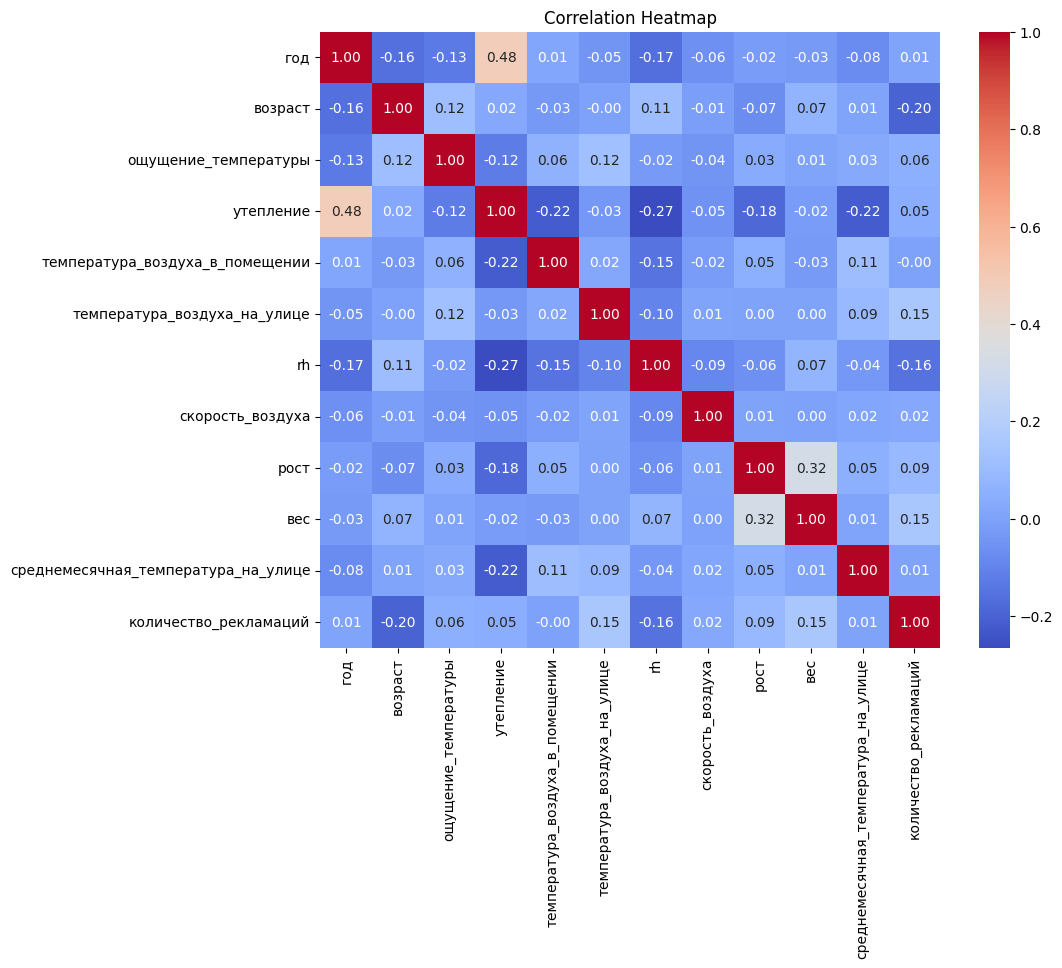

In [150]:
correlation_matrix = df[numerical_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


Возьмем пары столбцов , у  которых модуль корреляции больше или равен 0.2 , построим их scatterplot и исследуем зависимость


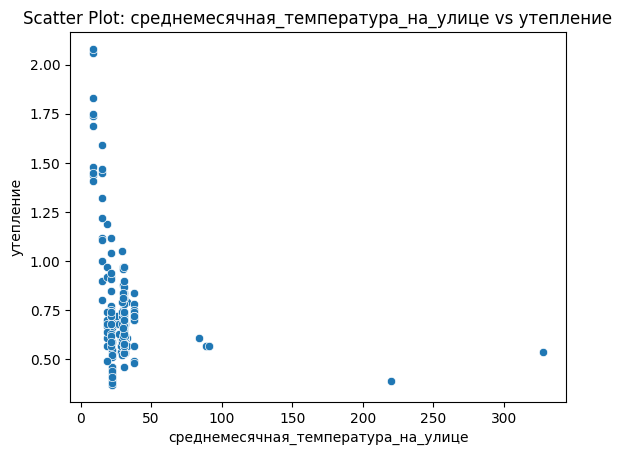

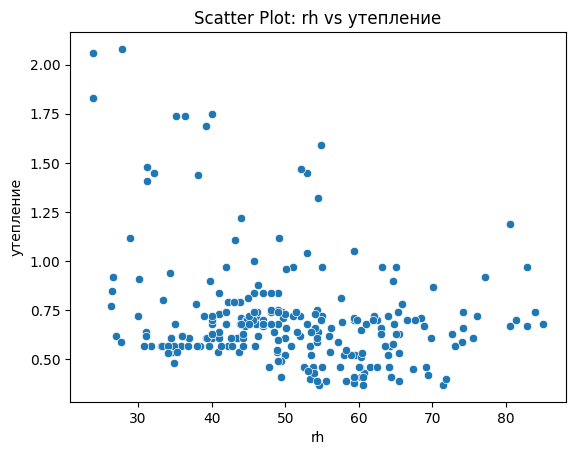

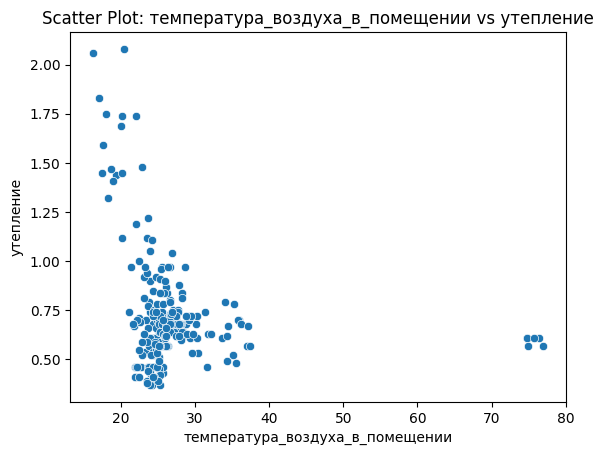

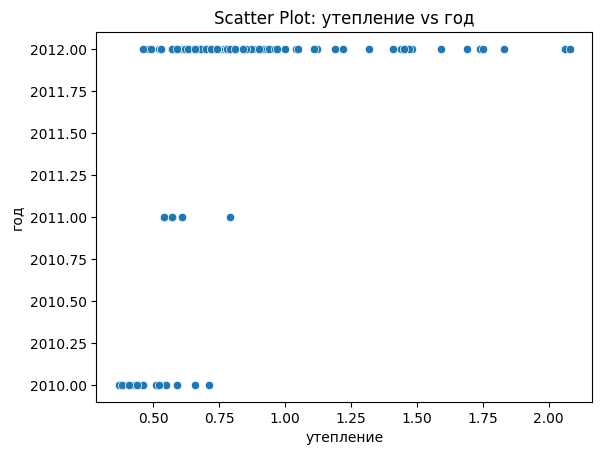

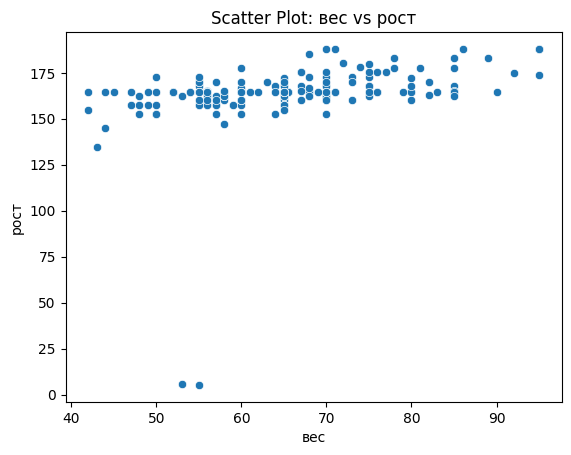

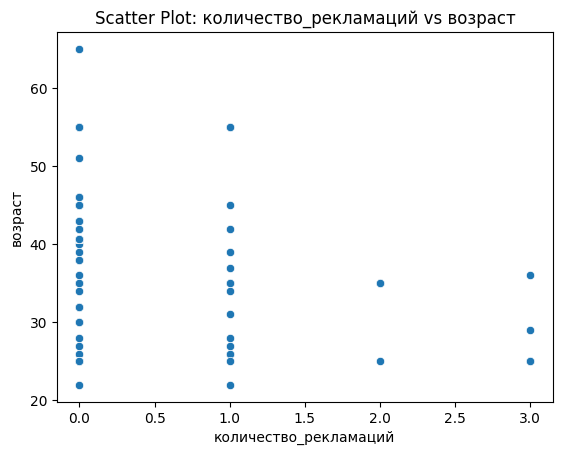

In [151]:
# Формирование списка уникальных пар столбцов с корреляцией >= 0.2
correlated_pairs = set()
for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) >= 0.2:
            correlated_pairs.add((correlation_matrix.columns[i], correlation_matrix.columns[j]))

# Построение scatterplot для каждой уникальной пары столбцов с корреляцией >= 0.2
for pair in correlated_pairs:
    sns.scatterplot(x=df[pair[0]], y=df[pair[1]])
    plt.title(f'Scatter Plot: {pair[0]} vs {pair[1]}')
    plt.xlabel(pair[0])
    plt.ylabel(pair[1])
    plt.show()